# WISE process evaluation

This notebook evaluates the three applications in **WISE: Actionable Norm-Based Scoring for Process Mining** by Urszula Jessen, Dirk Fahland and Francesca Zerbato. It covers the 34 result items and draws **Figures 3–5** from the verified datasets.

`wise.evaluation.paper` performs the assessments, scoring, evidence coverage, priorities, layer explanations and numerical checks. The notebook configures the calls and presents their results.

The comparison tables show which computed values agree with the paper, which are historical records, and which could not be computed. Matching a reported value checks the calculation; understanding the original events also requires review of the adapter rules and source records.

Run all cells in the dedicated environment. Saved outputs record an earlier run; check the source identity and norm against your current run before using them. Keep configured data-folder values out of the notebook.


## 1. Environment and data

Install the frozen package into a dedicated Python 3.11+ environment, from the repository root:

```sh
python -m pip install ".[notebook]"
```

Alternatively, run `bash setup_environment.sh` from this notebook folder. It creates a dedicated environment, installs a snapshot of this repository, and registers the **WISE paper (frozen)** kernel. The snapshot keeps packaging writes inside this folder. Rerun setup after a library update, then restart the kernel.

Start its JupyterLab with `bash start_jupyter.sh` once `WISE_PAPER_DATA` is set, or pass the data folder as the launch script’s single argument. Select **WISE paper (frozen)** as the kernel.

The frozen package uses the import name `wise`, also used by the living package. Use one of them per environment. This notebook requires the frozen 1.0.0 package and its documented paper API.

Before starting the notebook, set **one** environment variable, `WISE_PAPER_DATA`, to the directory holding the public source logs. The value is never printed or stored in the notebook. The library searches subfolders, verifies source identity and shares cached results between calls.

Required filenames, case-insensitive:

- `BPI_Challenge_2019.csv`
- `BPI_Challenge_2013_incidents.xes.gz`
- `BPI Challenge 2017.xes.gz`

A missing verified source is shown as **not computed**, rather than replaced with a reference value. The exact BPIC’19 export is required; an alternative export needs a documented conversion and matching identity.

Run with the notebook folder as the working directory. Optional exports stay in the notebook output folder. Set `SAVE_FIGURES = False` to display figures without saving them.

In [1]:
import os
from pathlib import Path

try:
    import wise
except ImportError:
    raise RuntimeError("Install the frozen package in the selected kernel environment.") from None

if wise.__version__ != "1.0.0":
    raise RuntimeError("Select the frozen 1.0.0 package environment.")
try:
    from wise.evaluation import paper, DataNotAvailable
except ImportError:
    raise RuntimeError(
        "The installed package does not provide wise.evaluation.paper. "
        "Install this repository with its notebook extra (see README) and restart the kernel."
    ) from None

if set(paper.ITEMS) != set(range(1, 35)):
    raise RuntimeError("The documented 34-item paper API is not available.")
if not os.environ.get("WISE_PAPER_DATA"):
    raise RuntimeError("Set WISE_PAPER_DATA before running the notebook.")

from IPython.display import display, Markdown
import matplotlib.pyplot as plt

SAVE_FIGURES = True
NOTEBOOK_ROOT = Path.cwd().resolve()
if NOTEBOOK_ROOT.name != "notebooks":
    raise RuntimeError("Run with the notebook folder as the working directory.")
OUTPUT_DIR = NOTEBOOK_ROOT / "outputs"

print("Frozen package ready; numerical results use the paper API.")

Frozen package ready; numerical results use the paper API.


In [2]:
%matplotlib inline

def show_result(function):
    """Present a library return value without computing or substituting results."""
    try:
        result = function()
    except DataNotAvailable:
        display(Markdown(
            "**Not computed:** the required verified source is unavailable. "
            "The comparison table records this dependency."
        ))
        return
    display(result)


def show_figure(function, stem):
    """Present the returned figure; optional exports contain no source records."""
    try:
        figure = function()
    except DataNotAvailable:
        display(Markdown("**Not computed:** the required verified source is unavailable."))
        return
    if SAVE_FIGURES:
        output = OUTPUT_DIR.resolve()
        if not output.is_relative_to(NOTEBOOK_ROOT):
            raise RuntimeError("Figure exports must remain inside the notebook folder.")
        output.mkdir(exist_ok=True)
        figure.savefig(output / (stem + ".png"), dpi=220, bbox_inches="tight")
        figure.savefig(output / (stem + ".svg"), bbox_inches="tight")
    display(figure)
    plt.close(figure)

## 2. Tables 3–4 and worked arithmetic — items 1–2

The additional balance constraint is outside scope for all five illustrative cases. The library applies Finance and Logistics raw weights and renormalises over evaluated constraints. Outside scope, unavailable evidence and evaluated zero are distinct.

Table 3 is the illustrative norm; it is separate from the ten-criterion empirical BPIC’19 norm.

In [3]:
display(paper.table_3())

,layer,type,description,params,applicability,Finance,Logistics
id,,,,,,,
c1,Core completeness,presence,Require an invoice receipt,"{'activity': ['Record Invoice Receipt'], 'm': 1}",always,0.20,0.25
c2,Receipt-to-invoice timing,lag,Invoice timeliness: GR → INV within 10 days,"{'a': ['Record Goods Receipt'], 'b': ['Record ...",always,0.45,0.15
c3,Match consistency,balance,Amount consistency: invoiced amount matches re...,"{'attr_x': 'amount', 'activities_x': ['Record ...",always,0.20,0.05
c4,Match consistency,balance,GR amount consistency: ordered amount matches ...,"{'attr_x': 'amount', 'activities_x': ['Create ...",{'flow_type': ['DF1']},0.05,0.25
c5,Handling discipline,singularity,Limit delivery fragmentation,"{'activity': ['Record Goods Receipt'], 'k': 2,...",always,0.05,0.45
c6,Exception discipline,exclusion,Avoid invoice cancellations,{'activity': ['Cancel Invoice Receipt']},always,0.10,0.10


In [4]:
show_result(paper.item_01_table_4)

,non-zero violations,S(Finance),S(Logistics)
case,,,
σA,ν_c2 = 0.75,0.6625,0.8875
σB,ν_c5 = 0.6667,0.9667,0.7000
σC,ν_c3 = 0.65,0.8700,0.9675
σD,ν_c6 = 1,0.9000,0.9000
σE,"ν_c1 = 1, ν_c2 = 1, ν_c3 = 1",0.1500,0.5500


In [5]:
show_result(paper.item_02_worked_arithmetic)

,computed
quantity,
"sat(z; 10, 20) at z = 8",0.000000
"sat(z; 10, 20) at z = 15",0.250000
"sat(z; 10, 20) at z = 20",0.500000
"sat(z; 10, 20) at z = 30",1.000000
"lag constraint c2 (δ = 10 d, Δ = 20 d) at a lag in days of 10",0.000000
"lag constraint c2 (δ = 10 d, Δ = 20 d) at a lag in days of 20",0.500000
"lag constraint c2 (δ = 10 d, Δ = 20 d) at a lag in days of 30",1.000000
"occurrence limit c5 (k = 2, K = 3) at a count of 3",0.333333
"occurrence limit c5 (k = 2, K = 3) at a count of 4",0.666667


## 3. BPIC’19 assessment specification — Table 5 and items 3–7

The scored case is a purchase-order item. Purchasing document, company, spend area and vendor describe whole-case context. The library preserves the four flow categories and explicit missing group labels.

Changing view changes importance weights, not the original criterion assessments. The primary comparison uses flat scoring, case-count scaling, the scored-population reference and no shrinkage. The raw multiplier of a layer applies to every criterion in that layer; it is not an equal allocation of a layer total.

In [6]:
display(paper.table_5())

,recorded condition,deviation scale,layer,scope,evidence,w(Balanced),w(Completion),w(Operations)
criterion,,,,,,,,
C01,No recorded invoice receipt,binary,Completion,non-consignment,"absence within recorded history, not proof of ...",1,3,1
C02,No recorded clearing,binary,Completion,non-consignment,"absence within recorded history, not proof of ...",1,3,1
C03,No recorded goods or service receipt,binary,Completion,DF1 or DF2,,1,3,1
C04,Long observed invoice-to-clearing lag,0 at 30; 1 at 90,Timing,non-consignment,both first timestamps observed and plausible; ...,1,2,1
C05,Invoice precedes goods or service receipt,binary,Timing,DF1,both first timestamps observed and plausible; ...,1,2,1
C06,Invoice-receipt cancellation recorded,binary,Rework,all,,1,1,2
C07,Price or quantity edits recorded,0 at 0; 1 at 3,Rework,all,,1,1,2
C08,Repeated invoice receipt,0 at 1; 1 at 4,Rework,non-consignment,,1,1,2
C09,Recorded user-attributed events,0 at 5; 1 at 15,Effort proxy,all,every event resource usable; a missing or unus...,1,1,3


### Source events, PO items and purchasing documents

In [7]:
show_result(paper.item_03_log_size)

events       1595923
po_items      251734
documents      76349
Name: BPIC'19, dtype: int64

### Case population by flow category

In [8]:
show_result(paper.item_04_flow_categories)

DF2            221010
DF1             15182
Consignment     14498
two_way          1044
Name: PO items, dtype: int64

### Company-by-spend-area groups

In [9]:
show_result(paper.item_05_slices)

30

### Scored population under each view

In [10]:
show_result(paper.item_06_scored_cases)

Balanced      251734
Completion    251734
Operations    251734
Name: scored PO items, dtype: int64

### Mean weighted evidence coverage under each view

In [11]:
show_result(paper.item_07_mean_coverage)

Balanced      0.787570
Completion    0.866370
Operations    0.669052
Name: mean coverage, dtype: float64

## 4. Timing evidence and Figure 3 — items 8–12

C04 uses the earliest successfully parsed invoice and clearing timestamps. The selected endpoints must pass the adapter’s plausibility checks, and their lag must be non-negative. Coverage measures available in-scope weight; it does not certify a complete log.

Figure 3 uses the complete library-produced distributions for the C04-evaluable populations. The notebook does not reconstruct curves from medians, sort lag arrays or calculate an empirical distribution.

### C04-evaluable and positive Packaging items

In [12]:
show_result(paper.item_08_c04_evaluable)

evaluable    76608
positive     64068
Name: Packaging, C04, dtype: int64

### Evaluable populations and medians

In [13]:
show_result(paper.item_09_lag_medians)

,n,median_days
Packaging,76608,69.040972
Remaining groups,106661,28.929167


### The same comparison restricted to DF2

In [14]:
show_result(paper.item_10_lag_medians_df2)

,n,median_days
Packaging,73157,70.139583
Remaining groups,100142,29.101389


### Figure 3 — cumulative invoice-to-clearing lag distributions (item 11)

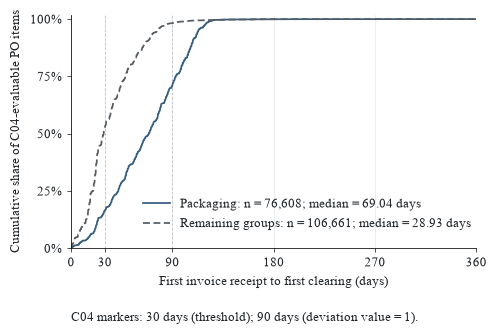

In [15]:
show_figure(paper.figure_3, "fig3_lag")

### Worked PO item and evidence states (item 12)

The library returns the selected item, endpoint timestamps, severity, weighted contribution, score and evidence coverage. Read them together to understand how this case was assessed.

In [16]:
show_result(paper.item_12_worked_po_item)

item                              4507005472_00040
first_invoice_receipt             2018-02-16 10:15
first_clearing                    2018-04-26 11:14
lag_days                                 69.040972
deviation                                 0.650683
evaluable_criteria                               7
contribution                              0.092955
other_nonzero                                    0
state.C05                             out_of_scope
state.C09                missing_resource_evidence
state.C10                missing_resource_evidence
score                                     0.907045
in_scope_criteria                                9
coverage                                  0.777778
group_median_days                        69.040972
Name: worked PO item, dtype: object

## 5. Group priorities and Figure 4 — items 13–20

The library compares mean penalties with the full scored population and computes the Priority Index. Layer explanations remain signed: negative offsets are included before the total is clipped at zero. Rounded plotted components need not sum exactly to a separately rounded printed total.

These comparisons identify records to investigate. They are not causal explanations, financial-loss estimates or measured staffing effort.

### Balanced population mean penalty

In [17]:
show_result(paper.item_13_population_mean_penalty)

0.1013579109646243

### Packaging group priority

In [18]:
show_result(paper.item_14_packaging)

mean_penalty         0.117624
scored          109199.000000
gap                  0.016266
pi                1776.191040
Name: companyID_0000 / Packaging, dtype: float64

### Logistics group priority

In [19]:
show_result(paper.item_15_logistics)

mean_penalty       0.228143
scored          5242.000000
gap                0.126785
pi               664.607179
Name: companyID_0000 / Logistics, dtype: float64

### Group coverage

In [20]:
show_result(paper.item_16_slice_coverage)

companyID_0000 / Packaging    0.788831
companyID_0000 / Logistics    0.706683
Name: mean coverage, dtype: float64

### Signed layer contributions

In [21]:
show_result(paper.item_17_layer_contributions)

,Completion,Timing,Rework,Effort proxy,sum,Priority Index
companyID_0000 / Packaging,-332.420985,2365.436368,-267.950108,11.125766,1776.191040,1776.191040
companyID_0000 / Logistics,811.132774,-154.248298,10.535362,-2.812658,664.607179,664.607179


### Figure 4 — signed explanations on a common scale (item 18)

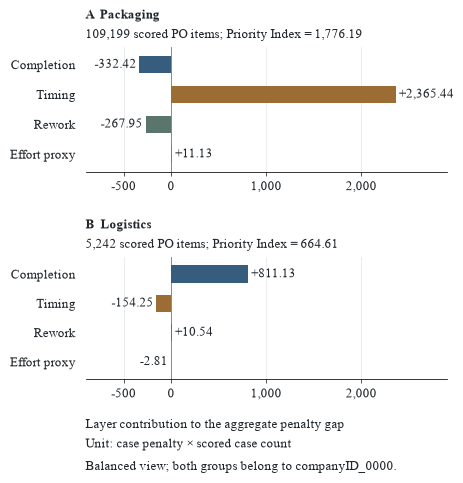

In [22]:
show_figure(paper.figure_4, "fig4_layers")

### Recorded Logistics absences (item 19)

In [23]:
show_result(paper.item_19_logistics_absences)

no_invoice_receipt    3260
no_clearing           3507
items                 5242
Name: companyID_0000 / Logistics, dtype: int64

### Packaging vendor concentration (item 20)

The concentration measure uses the sum of case penalties within vendor groups, not vendor Priority Indices.

In [24]:
show_result(paper.item_20_vendor_concentration)

vendors                   266
vendors_for_80_percent     16
Name: companyID_0000 / Packaging, dtype: int64

## 6. Investigation shortlists and Figure 5 — items 21–25

The library returns sorted shortlist membership comparisons, tie checks and Jaccard similarities. The view comparison uses positive-priority purchasing-document lists. The ranking-policy comparison holds Balanced case penalties, the scored population and the group definitions fixed. The notebook does not recalculate rankings or overlaps.

### Purchasing-document shortlist comparisons

In [25]:
show_result(paper.item_21_document_shortlists)

,shared,distinct,jaccard,length_first,length_second,tie_across_cut
views,,,,,,
Balanced / Completion,18,22,0.818182,20,20,False
Balanced / Operations,10,30,0.333333,20,20,False
Completion / Operations,8,32,0.250000,20,20,False


### First two groups under each view

In [26]:
show_result(paper.item_22_first_two_slices)

,first,PI first,second,PI second
view,,,,
Balanced,companyID_0000 / Packaging,1776.191040,companyID_0000 / Logistics,664.607179
Completion,companyID_0000 / Packaging,1636.727524,companyID_0000 / Logistics,1070.670971
Operations,companyID_0000 / Packaging,1134.709340,companyID_0000 / Logistics,446.286369


### Company-by-spend-area overlap across views

In [27]:
show_result(paper.item_23_top_ten_overlap)

Completion    9
Operations    8
Name: shared with the Balanced top ten, dtype: int64

### Mean penalty, total penalty and stabilised PI policies

In [28]:
show_result(paper.item_24_ranking_policies)

mean_penalty      6
total_penalty     4
gamma20          10
Name: shared with the primary PI top ten, dtype: int64

### Figure 5 — shortlist overlap comparisons (item 25)

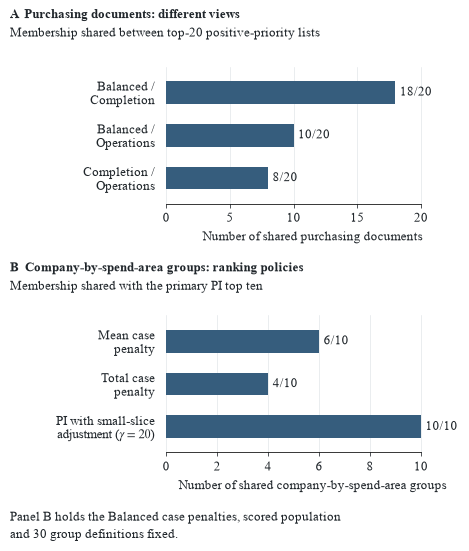

In [29]:
show_figure(paper.figure_5, "fig5_shortlists")

## 7. Incident transfer — Table B1 and items 26–30

The incident adapter retains uncertainty from missing team observations, timestamp ties and changing context. Repeated substatus observations and immediate returns are recorded patterns; the illustrative thresholds do not establish a service commitment or failed resolution. All returned calculations use the library’s incident configuration.

In [30]:
display(paper.table_b1())

,recorded condition,deviation scale,layer,w(Balanced),w(Routing),w(Timing)
criterion,,,,,,
C01,Observed support-team changes,"r(x; 2, 4)",Routing,1,3,1
C02,Immediate return to prior support team (compre...,"r(x; 0, 2)",Routing,1,3,1
C03,Repeated substatus observations beyond first o...,"r(x; 2, 8)",Recorded patterns,1,1,1
C04,Wait - User observed (not abuse),binary,Recorded patterns,1,1,1
C05,Long observed trace span (not resolution or se...,"r(x; 7, 23)",Timing,1,1,3
C06,Active status observed after Completed (not ce...,binary,Reactivation,1,1,2


### Incident population and product groups

In [31]:
show_result(paper.item_26_incident_log_size)

incidents     7554
events       65533
groups         704
Name: BPIC'13 incidents, dtype: int64

### Worked incident and return contribution

In [32]:
show_result(paper.item_27_worked_incident)

incident              1-530458987
product_group             PROD542
returns                         5
deviation_c02                 1.0
evaluable_criteria              6
contribution             0.166667
case_penalty                  1.0
Name: worked incident, dtype: object

### Balanced incident mean penalty

In [33]:
show_result(paper.item_28_incident_mean_penalty)

0.16938531914241436

### PROD542 priority and signed explanations

In [34]:
show_result(paper.item_29_prod542)

top_group                    PROD542
mean_penalty                0.665994
scored                            75
pi                         37.245645
layer.Routing              17.075672
layer.Recorded patterns    10.615626
layer.Timing                9.071557
layer.Reactivation          0.482791
largest_layer                Routing
Name: highest Priority Index, dtype: object

### PROD424 priority

In [35]:
show_result(paper.item_30_prod424)

mean_penalty      0.205114
scored          882.000000
pi               31.512825
Name: PROD424, dtype: float64

## 8. Lending transfer — Table B2 and items 31–32

The application is the scored case. Lifecycle-specific work starts and reconciled offer identities remain part of the library’s adapter policy. The view comparison changes weights while retaining criterion results and groups. Domain scores are not calibrated for cross-domain comparison.

In [36]:
display(paper.table_b2())

,recorded condition,deviation scale,layer,scope,evidence,w(Balanced),w(Timeliness),w(Interaction)
criterion,,,,,,,,
C01,long recorded span; not completed cycle time o...,"r(x; 30, 30)",Timing,all applications,"at least two events, every timestamp timezone-...",1,4,1
C02,sum over W_ activities of max(number of START ...,"r(x; 0, 5)",Interaction,all applications,all event activity and lifecycle values present,1,1,3
C03,distinct recorded W_ START resource identifier...,"r(x; 2, 5)",Interaction,all applications,"activity and lifecycle complete, every W_ STAR...",1,1,3
C04,distinct observed offers associated with an ap...,"r(x; 1, 3)",Offer,any recorded O_ activity,activity and lifecycle complete and fully reco...,1,1,1
C05,number of COMPLETE A_Incomplete state records;...,"r(x; 0, 3)",Interaction,all applications,all event activity and lifecycle values present,1,1,3


### Lending population and evidence coverage (item 31)

In [ ]:
show_result(paper.item_31_lending_log_size)

### Highest-priority group under each view (item 32)

In [ ]:
show_result(paper.item_32_lending_first_slices)

## 9. Numerical consistency and source identity — items 33–34

The consistency result distinguishes configurations and views **rerun here** from the **recorded** 15-configuration, 44-view check in the paper. A historical recorded number must not be presented as a newly executed experiment. The declared numerical tolerance is 1e-8, while scope and evidence states require exact agreement.

The source-identity result reports the BPIC’19 filename, rows, bytes and checksum, without a data-directory value. Prepared-input parity checks the numerical pipeline after adaptation; interpretation of original records requires the domain adapter and source evidence.

In [ ]:
show_result(paper.item_33_consistency_check)

In [ ]:
show_result(paper.item_34_input_identity)

## 10. Printed-versus-computed comparison for all 34 items

`compare()` owns the expected values, rounding tolerances and agreement calculations. `summary()` owns the item-level aggregation. No expected experimental outputs are inserted by the notebook.

A not-computed result remains visible and does not count as agreement. Figures are drawn from library results; the numeric items provide their underlying checks. Tables 1, 2 and 6 describe requirements, notation and evaluation scope rather than additional computational experiments.

In [ ]:
comparison = paper.compare()
display(comparison)
item_summary = paper.summary(comparison)
display(item_summary)

In [ ]:
for differences in item_summary["differ"]:
    if differences:
        raise AssertionError("A computed result differs from the printed value; inspect the comparison.")
display(Markdown("The computed values agree with the paper. Review historical records and any values marked not computed separately."))

## 11. Reading and sharing the result

Use the comparison and its notes to distinguish source-record execution, prepared-input consistency, illustrative calculations and missing dependencies. Evidence coverage is distinct from compliance and from source-log completeness. Positive and negative layer contributions are interpreted together.

Exports are generated in the ignored notebook output folder. Review saved outputs and execution counts before sharing or committing the notebook. Do not include source logs, extracted manuscript text or a configured data-directory value. The notebook’s saved source stays portable; results are obtained by rerunning the cited library.